<a href="https://colab.research.google.com/github/raitig/Machine-Learning-/blob/main/Face_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()


Saving image.zip to image.zip


In [38]:
%matplotlib inline
import os, glob, zipfile, time, urllib.request
from base64 import b64decode, b64encode
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Javascript
from google.colab import files
from google.colab.output import eval_js

print("OpenCV version:", cv2.__version__)
print("FaceDetectorYN available  :", hasattr(cv2, "FaceDetectorYN"))
print("FaceRecognizerSF available:", hasattr(cv2, "FaceRecognizerSF"))
print("Setup OK")

OpenCV version: 5.0.0
FaceDetectorYN available  : True
FaceRecognizerSF available: True
Setup OK


Total images inside zip: 202599
Extracted images: 3000
Landmarks CSV loaded: True


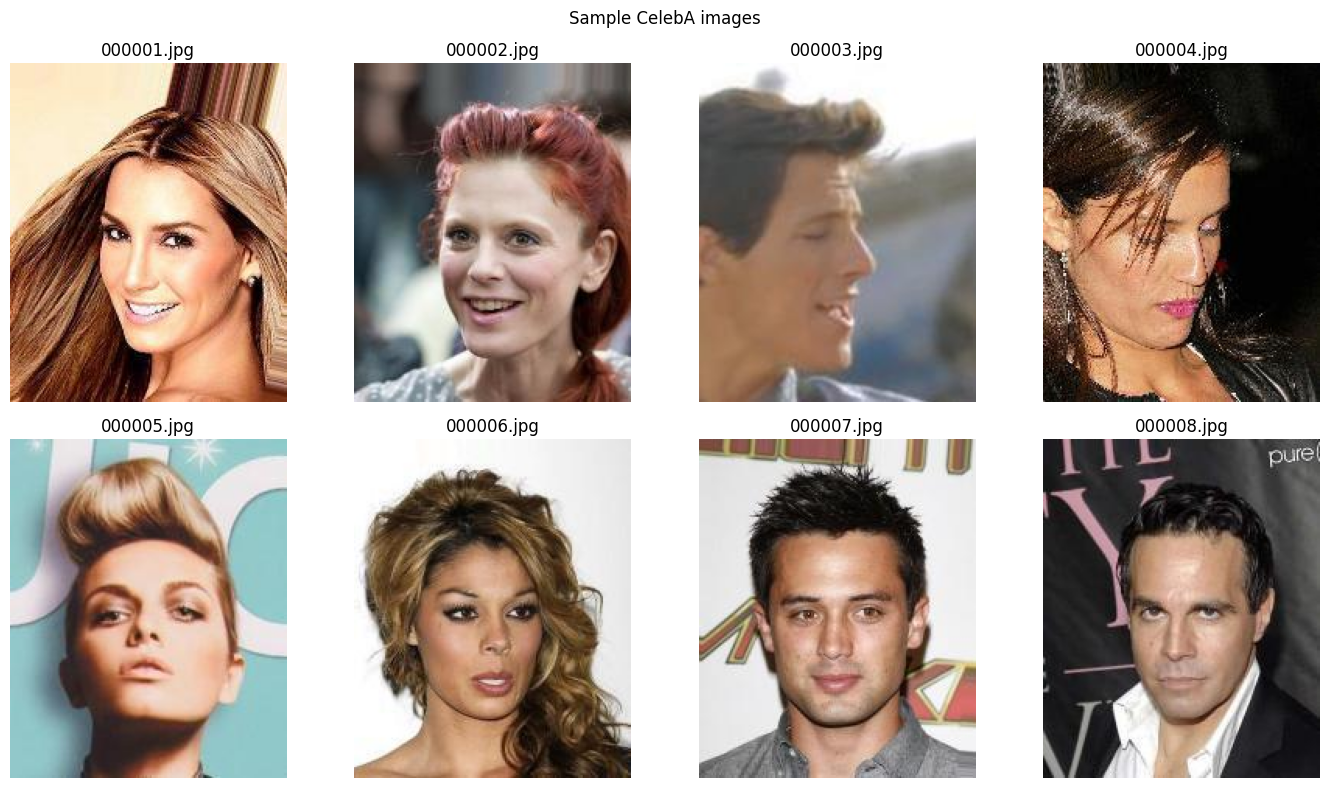

In [39]:
ZIP_PATH    = "/content/image.zip"          # the zip you uploaded
EXTRACT_DIR = "/content/celeba_images"
N_EXTRACT   = 3000                          # extract only the first N images (fast). Increase if you want more.

image_paths = []
if os.path.exists(ZIP_PATH):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        all_imgs = sorted(n for n in z.namelist() if n.lower().endswith((".jpg", ".jpeg", ".png")))
        print("Total images inside zip:", len(all_imgs))
        z.extractall(EXTRACT_DIR, all_imgs[:N_EXTRACT])
    image_paths = sorted(glob.glob(os.path.join(EXTRACT_DIR, "**", "*.jpg"), recursive=True))
    print("Extracted images:", len(image_paths))
else:
    print("image.zip not found in /content. Upload it first (the dataset steps will be skipped).")

# Optional CSV files (only used if you uploaded them to /content as well)
def find_csv(name):
    hits = glob.glob("/content/**/" + name, recursive=True)
    return hits[0] if hits else None

lm_path = find_csv("list_landmarks_align_celeba.csv")
landmarks_df = pd.read_csv(lm_path).set_index("image_id") if lm_path else None
print("Landmarks CSV loaded:", landmarks_df is not None)

if image_paths:
    fig, axes = plt.subplots(2, 4, figsize=(14, 8))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, p in zip(axes.ravel(), image_paths[:8]):
        ax.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        ax.set_title(os.path.basename(p))
    plt.suptitle("Sample CelebA images")
    plt.tight_layout()
    plt.show()

In [41]:
# ---------- Models (downloaded automatically, small files) ----------
import os
import urllib.request
import numpy as np
import cv2
from base64 import b64decode
import matplotlib.pyplot as plt
from IPython.display import display, Javascript
from google.colab import files
from google.colab.output import eval_js

MODEL_DIR = "/content/models"
os.makedirs(MODEL_DIR, exist_ok=True)
BASE = "https://github.com/opencv/opencv_zoo/raw/main/models/"
MODELS = {
    "yunet": ("face_detection_yunet_2023mar.onnx", BASE + "face_detection_yunet/face_detection_yunet_2023mar.onnx"),
    "sface": ("face_recognition_sface_2021dec.onnx", BASE + "face_recognition_sface/face_recognition_sface_2021dec.onnx"),
}

def download_model(key):
    fname, url = MODELS[key]
    path = os.path.join(MODEL_DIR, fname)
    ok = lambda: os.path.exists(path) and os.path.getsize(path) > 100000
    if not ok():
        try:
            urllib.request.urlretrieve(url, path)
        except Exception as e:
            print("Could not download", fname, "->", e)
    return path if ok() else None


class FaceEngine:
    COSINE_THRESHOLD = 0.363   # recommended threshold for SFace (cosine similarity)

    def __init__(self):
        self.yunet = None
        self.sface = None
        yp, sp = download_model("yunet"), download_model("sface")
        try:
            if yp:
                self.yunet = cv2.FaceDetectorYN.create(yp, "", (320, 320), 0.8, 0.3, 5000)
            if sp:
                self.sface = cv2.FaceRecognizerSF.create(sp, "")
        except Exception as e:
            print("Model loading problem:", e)

        self.haar = None
        if hasattr(cv2, "CascadeClassifier"):
            try:
                self.haar = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
            except Exception:
                self.haar = None

        print("Detector  :", "YuNet (deep learning)" if self.yunet is not None else "Haar cascade (fallback)" if self.haar is not None else "None")
        print("Recognizer:", "SFace (deep learning)" if self.sface is not None else "NOT available (detection only)")

    def detect(self, bgr):
        h, w = bgr.shape[:2]
        if self.yunet is not None:
            self.yunet.setInputSize((w, h))
            _, faces = self.yunet.detect(bgr)
            if faces is None:
                return []
            return [dict(box=tuple(int(v) for v in f[:4]), row=f, score=float(f[-1])) for f in faces]
        if self.haar is not None:
            gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
            rects = self.haar.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))
            return [dict(box=tuple(int(v) for v in r), row=None, score=1.0) for r in rects]
        return []

    def embed(self, bgr, face):
        if self.sface is None or face["row"] is None:
            return None
        aligned = self.sface.alignCrop(bgr, face["row"])
        feat = self.sface.feature(aligned).flatten().astype(np.float32)
        return feat / (np.linalg.norm(feat) + 1e-9)


engine = FaceEngine()
gallery = {}

def enroll(name, emb):
    gallery.setdefault(name, []).append(emb)

def identify(emb):
    best_name, best = None, -1.0
    for n, embs in gallery.items():
        s = float(np.max(np.array(embs) @ emb))
        if s > best:
            best, best_name = s, n
    if best >= engine.COSINE_THRESHOLD:
        return best_name, best
    return None, best

def largest(faces):
    return max(faces, key=lambda f: f["box"][2] * f["box"][3])

def limit_size(img, max_side=1280):
    h, w = img.shape[:2]
    s = max_side / max(h, w)
    return cv2.resize(img, (int(w * s), int(h * s))) if s < 1 else img

def analyse(bgr):
    results = []
    for f in engine.detect(bgr):
        emb = engine.embed(bgr, f)
        if emb is None:
            results.append(dict(box=f["box"], text="FACE", color=(255, 120, 0), granted=None, score=f["score"]))
        elif not gallery:
            results.append(dict(box=f["box"], text="FACE (nobody enrolled)", color=(255, 120, 0), granted=None, score=f["score"]))
        else:
            name, score = identify(emb)
            if name is not None:
                results.append(dict(box=f["box"], text="%s %.2f" % (name, score), color=(0, 200, 0), granted=True, score=score))
            else:
                results.append(dict(box=f["box"], text="UNKNOWN %.2f" % score, color=(0, 0, 255), granted=False, score=score))
    return results

def draw(bgr, results):
    out = bgr.copy()
    for r in results:
        x, y, w, h = r["box"]
        cv2.rectangle(out, (x, y), (x + w, y + h), r["color"], 2)
        cv2.putText(out, r["text"], (x, max(15, y - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, r["color"], 2)
    return out

def show(bgr, title=""):
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

def report(results):
    print("Faces found:", len(results))
    for i, r in enumerate(results, 1):
        if r["granted"] is True:
            print("  Face %d: ACCESS GRANTED -> %s" % (i, r["text"]))
        elif r["granted"] is False:
            print("  Face %d: ACCESS DENIED  -> %s" % (i, r["text"]))
        else:
            print("  Face %d: %s" % (i, r["text"]))
    if not results:
        print("  No face detected. Try a clearer, front-facing, well-lit photo.")

def data_url_to_bgr(data_url):
    raw = b64decode(data_url.split(",")[1])
    return cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)

def upload_image():
    print("Please choose a picture from your gallery / computer ...")
    up = files.upload()
    if not up:
        print("No file selected.")
        return None
    name = list(up.keys())[0]
    img = cv2.imdecode(np.frombuffer(up[name], np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        print("Could not read that file as an image.")
        return None
    return limit_size(img)

# ---------- Camera permission + capture (browser JavaScript) ----------
CAMERA_JS = '''
window.askCamera = function(question) {
  return new Promise(function(resolve) {
    const div = document.createElement('div');
    div.style.cssText = 'padding:14px;border:2px solid #4285f4;border-radius:8px;max-width:520px;font-family:sans-serif;margin:6px 0';
    div.innerHTML = '<p style="font-size:16px;margin:0 0 10px 0"><b>' + question + '</b></p>';
    const yes = document.createElement('button');
    yes.textContent = 'Yes, open my camera';
    yes.style.cssText = 'padding:8px 14px;margin-right:10px;background:#34a853;color:white;border:none;border-radius:4px;cursor:pointer';
    const no = document.createElement('button');
    no.textContent = 'No, I will upload a picture';
    no.style.cssText = 'padding:8px 14px;background:#ea4335;color:white;border:none;border-radius:4px;cursor:pointer';
    yes.onclick = function() { div.remove(); resolve('yes'); };
    no.onclick = function() { div.remove(); resolve('no'); };
    div.appendChild(yes); div.appendChild(no);
    document.querySelector('#output-area').appendChild(div);
  });
};

window.takePhoto = async function(quality) {
  const div = document.createElement('div');
  const capture = document.createElement('button');
  capture.textContent = 'Capture photo';
  capture.style.cssText = 'padding:8px 14px;margin-bottom:6px;background:#4285f4;color:white;border:none;border-radius:4px;cursor:pointer';
  div.appendChild(capture);
  const video = document.createElement('video');
  video.style.display = 'block';
  const stream = await navigator.mediaDevices.getUserMedia({video: true});
  document.body.appendChild(div);
  div.appendChild(video);
  video.srcObject = stream;
  await video.play();
  google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
  await new Promise(function(resolve) { capture.onclick = resolve; });
  const canvas = document.createElement('canvas');
  canvas.width = video.videoWidth;
  canvas.height = video.videoHeight;
  canvas.getContext('2d').drawImage(video, 0, 0);
  stream.getVideoTracks()[0].stop();
  div.remove();
  return canvas.toDataURL('image/jpeg', quality);
};
'''

def ask_camera(question):
    display(Javascript(CAMERA_JS))
    return eval_js('askCamera("%s")' % question)

def get_user_image(question="Are you interested to open your camera?"):
    answer = ask_camera(question)
    if answer == "yes":
        try:
            data = eval_js("takePhoto(0.9)")
            return limit_size(data_url_to_bgr(data)), "camera"
        except Exception as e:
            print("Camera could not be opened (%s)." % str(e)[:120])
            print("Falling back to picture upload.")
    else:
        print("Camera access not allowed. Please upload your picture from your gallery.")
    return upload_image(), "upload"

print("Engine and helpers are ready.")

Detector  : YuNet (deep learning)
Recognizer: SFace (deep learning)
Engine and helpers are ready.


Face detection rate on 100 random CelebA images: 100.0%


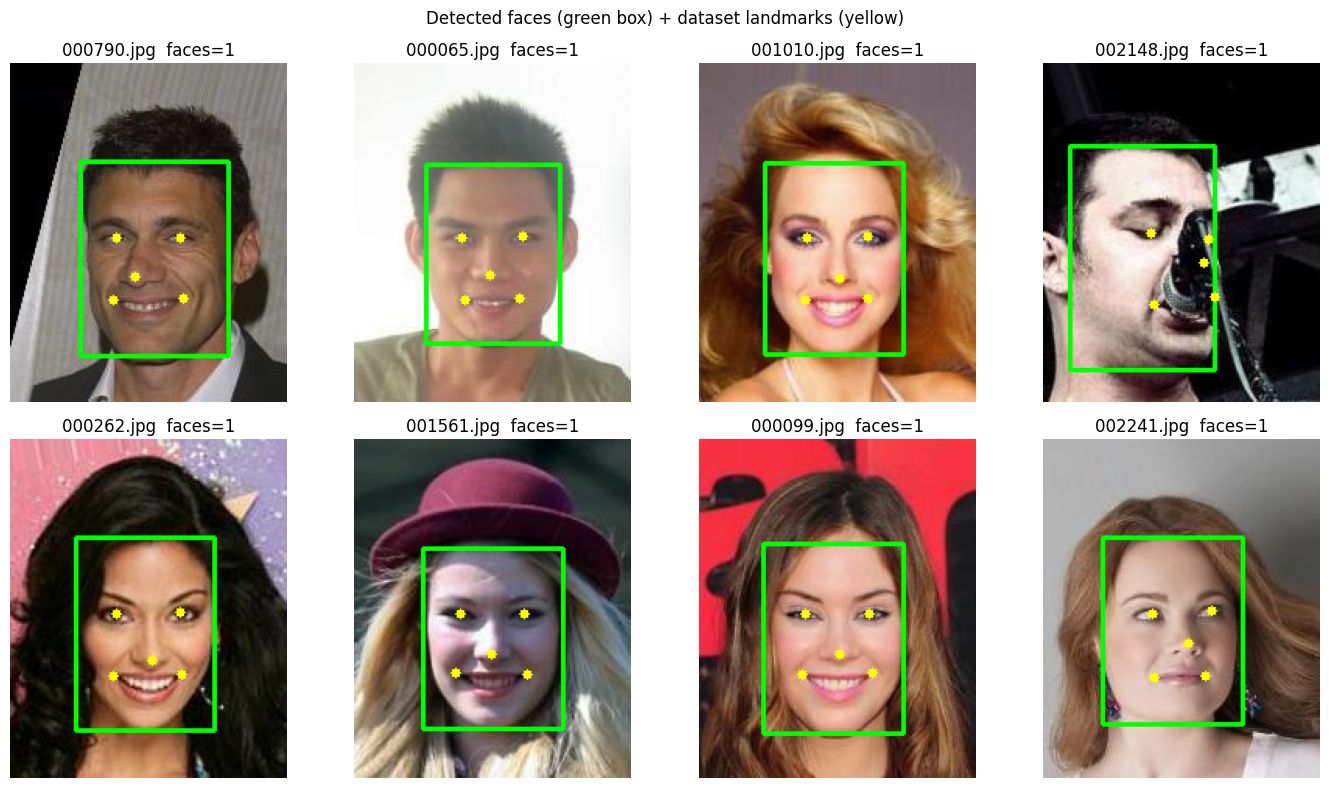

In [42]:
if not image_paths:
    print("Skipped: no CelebA images extracted.")
else:
    rng = np.random.default_rng(0)
    idx = rng.choice(len(image_paths), size=min(100, len(image_paths)), replace=False)
    detected, shown = 0, []
    for i in idx:
        img = cv2.imread(image_paths[i])
        faces = engine.detect(img)
        detected += 1 if faces else 0
        if len(shown) < 8:
            shown.append((img, faces, image_paths[i]))
    print("Face detection rate on %d random CelebA images: %.1f%%" % (len(idx), 100.0 * detected / len(idx)))

    fig, axes = plt.subplots(2, 4, figsize=(14, 8))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (img, faces, p) in zip(axes.ravel(), shown):
        vis = img.copy()
        for f in faces:
            x, y, w, h = f["box"]
            cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
        key = os.path.basename(p)
        if landmarks_df is not None and key in landmarks_df.index:
            row = landmarks_df.loc[key]
            for a, b in [("lefteye", None), ("righteye", None), ("nose", None), ("leftmouth", None), ("rightmouth", None)]:
                cv2.circle(vis, (int(row[a + "_x"]), int(row[a + "_y"])), 3, (0, 255, 255), -1)
        ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        ax.set_title("%s  faces=%d" % (key, len(faces)))
    plt.suptitle("Detected faces (green box)" + (" + dataset landmarks (yellow)" if landmarks_df is not None else ""))
    plt.tight_layout()
    plt.show()

Enrolled demo users: ['User_000001', 'User_000002', 'User_000003', 'User_000004', 'User_000005', 'User_000006', 'User_000007', 'User_000008', 'User_000009', 'User_000010']

Test 1 - enrolled person:
Faces found: 1
  Face 1: ACCESS GRANTED -> User_000001 1.00

Test 2 - 100 unenrolled people: wrongly accepted = 1 (false accept rate 1.0%)


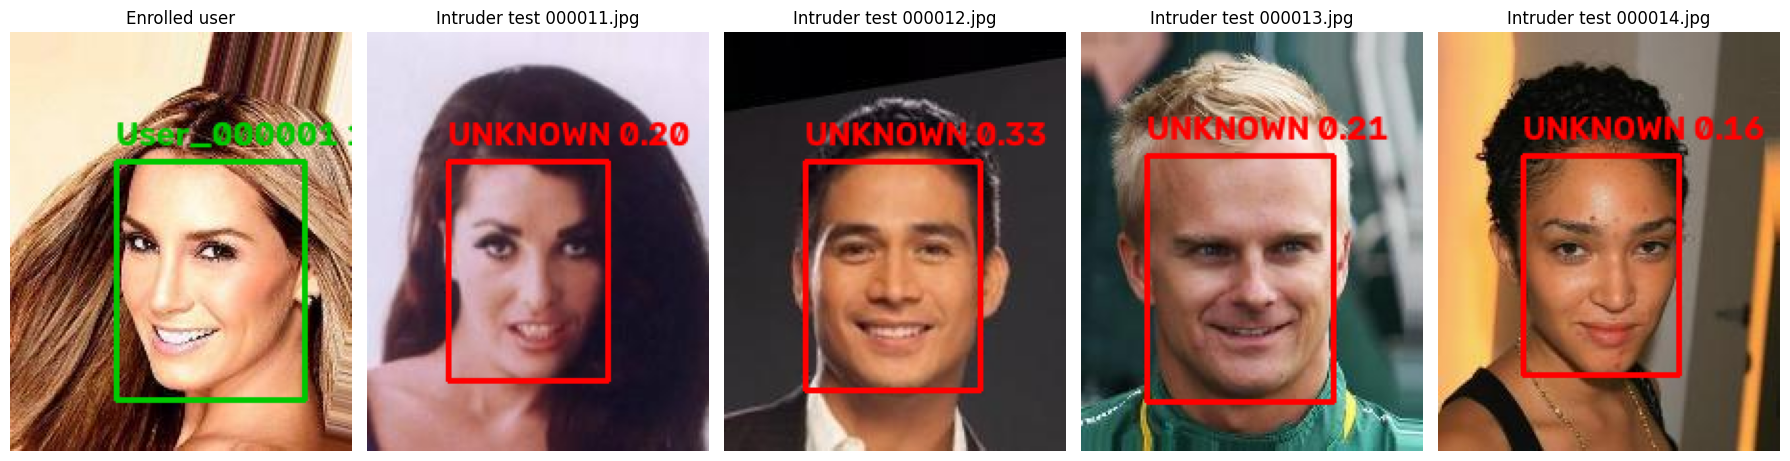

In [43]:
# Demo "authorized users": first 10 CelebA images are enrolled, then 100 other images are used as intruders.
if not image_paths:
    print("Skipped: no CelebA images extracted.")
elif engine.sface is None:
    print("Skipped: recognition model is not available (check internet access in Colab).")
else:
    gallery.clear()
    for p in image_paths[:10]:
        img = cv2.imread(p)
        faces = engine.detect(img)
        if faces:
            enroll("User_" + os.path.basename(p).split(".")[0], engine.embed(img, largest(faces)))
    print("Enrolled demo users:", list(gallery.keys()))

    # 1) an enrolled picture must be accepted
    img0 = cv2.imread(image_paths[0])
    print("\nTest 1 - enrolled person:")
    res0 = analyse(img0)
    report(res0)

    # 2) other (unenrolled) people must be rejected
    probes = image_paths[10:110]
    accepted = 0
    vis_list = []
    for p in probes:
        img = cv2.imread(p)
        res = analyse(img)
        if any(r["granted"] for r in res):
            accepted += 1
        if len(vis_list) < 4:
            vis_list.append((draw(img, res), os.path.basename(p)))
    print("\nTest 2 - %d unenrolled people: wrongly accepted = %d (false accept rate %.1f%%)" %
          (len(probes), accepted, 100.0 * accepted / max(1, len(probes))))

    fig, axes = plt.subplots(1, 5, figsize=(18, 5))
    for ax in axes:
        ax.axis("off")
    axes[0].imshow(cv2.cvtColor(draw(img0, res0), cv2.COLOR_BGR2RGB)); axes[0].set_title("Enrolled user")
    for ax, (v, n) in zip(axes[1:], vis_list):
        ax.imshow(cv2.cvtColor(v, cv2.COLOR_BGR2RGB)); ax.set_title("Intruder test " + n)
    plt.tight_layout()
    plt.show()

Enter your name to enroll: Raitig


<IPython.core.display.Javascript object>

Camera access not allowed. Please upload your picture from your gallery.
Please choose a picture from your gallery / computer ...


Saving Festive Night Portrait in Red Kurta (1).png to Festive Night Portrait in Red Kurta (1) (4).png
Enrolled 'Raitig' using upload. Authorized users now: ['User_000001', 'User_000002', 'User_000003', 'User_000004', 'User_000005', 'User_000006', 'User_000007', 'User_000008', 'User_000009', 'User_000010', 'Raitig', 'Reitig', 'Debajit', 'Gourab']


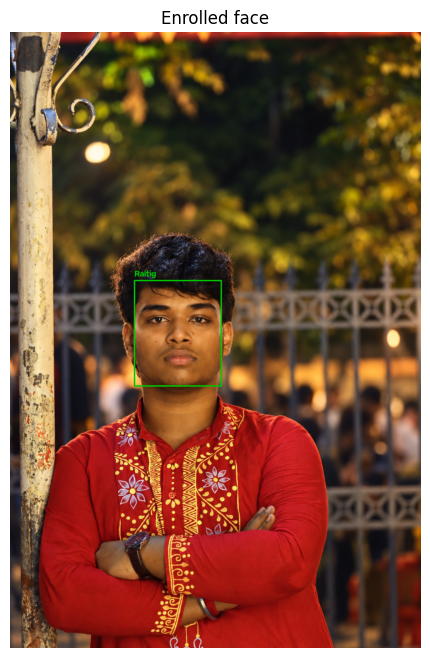

In [60]:
# Enroll YOURSELF as an authorized user.
name = input("Enter your name to enroll: ").strip() or "Me"
img, source = get_user_image("Are you interested to open your camera to enroll your face?")

if img is None:
    print("No image received. Run this cell again.")
else:
    faces = engine.detect(img)
    if not faces:
        print("No face detected. Run this cell again with a clearer, front-facing photo.")
    else:
        emb = engine.embed(img, largest(faces))
        if emb is None:
            print("Recognition model not available, so enrollment is not possible.")
        else:
            enroll(name, emb)
            print("Enrolled '%s' using %s. Authorized users now: %s" % (name, source, list(gallery.keys())))
        show(draw(img, [dict(box=largest(faces)["box"], text=name, color=(0, 200, 0))]), "Enrolled face")

<IPython.core.display.Javascript object>

Camera access not allowed. Please upload your picture from your gallery.
Please choose a picture from your gallery / computer ...


Saving Festive Night Portrait in Red Kurta (1).png to Festive Night Portrait in Red Kurta (1) (5).png
Image source: upload
Faces found: 1
  Face 1: ACCESS GRANTED -> Raitig 1.00


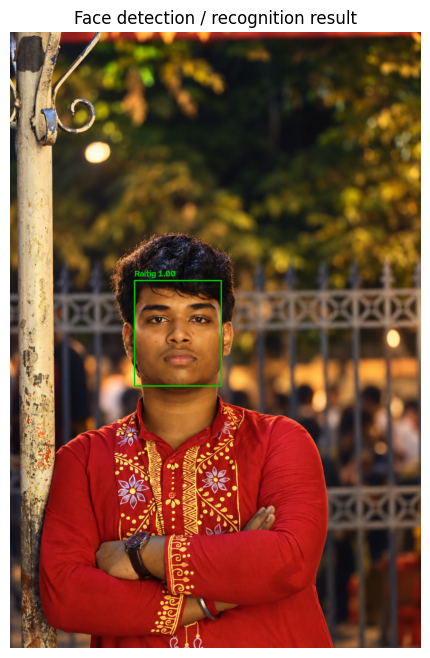

In [61]:
# Detect + recognize from ONE photo (camera snapshot, or upload if camera is not allowed).
img, source = get_user_image("Are you interested to open your camera?")

if img is None:
    print("No image received. Run this cell again.")
else:
    results = analyse(img)
    print("Image source:", source)
    report(results)
    show(draw(img, results), "Face detection / recognition result")

<IPython.core.display.Javascript object>

Camera access not allowed. Please upload your picture from your gallery.
Please choose a picture from your gallery / computer ...


Saving Festive Night Portrait in Red Kurta (1).png to Festive Night Portrait in Red Kurta (1) (6).png
Faces found: 1
  Face 1: ACCESS GRANTED -> Raitig 1.00


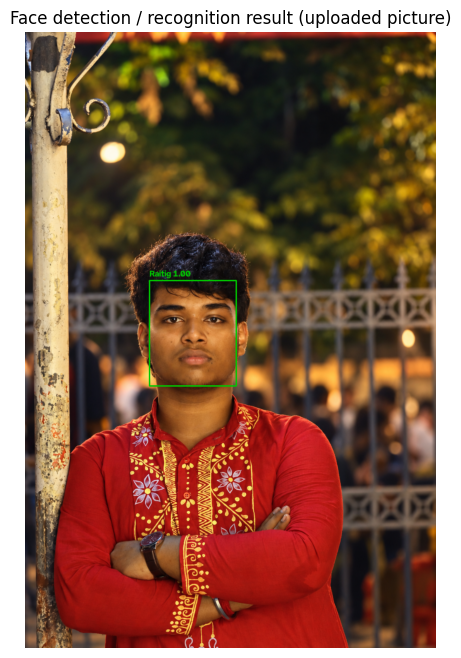

In [63]:
# LIVE real-time detection + recognition from the webcam.
# Click on the video (or the red text) to stop. It also stops automatically after MAX_SECONDS.
MAX_SECONDS = 120

LIVE_JS = '''
var video; var div = null; var stream; var captureCanvas; var imgElement; var labelElement;
var pendingResolve = null; var shutdown = false;

function stopLive() { shutdown = true; }

function removeDom() {
  stream.getVideoTracks()[0].stop();
  video.remove(); div.remove();
  video = null; div = null; stream = null; imgElement = null; captureCanvas = null; labelElement = null;
}

function onAnimationFrame() {
  if (!shutdown) { window.requestAnimationFrame(onAnimationFrame); }
  if (pendingResolve) {
    var result = "";
    if (!shutdown) {
      captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
      result = captureCanvas.toDataURL('image/jpeg', 0.8);
    }
    var lp = pendingResolve; pendingResolve = null; lp(result);
  }
}

async function createDom() {
  if (div !== null) { return stream; }
  div = document.createElement('div');
  div.style.border = '2px solid black'; div.style.padding = '3px'; div.style.width = '100%'; div.style.maxWidth = '640px';
  document.body.appendChild(div);

  const modelOut = document.createElement('div');
  modelOut.innerHTML = '<span>Status: </span>';
  labelElement = document.createElement('span');
  labelElement.innerText = 'Starting camera...';
  labelElement.style.fontWeight = 'bold';
  modelOut.appendChild(labelElement);
  div.appendChild(modelOut);

  video = document.createElement('video');
  video.style.display = 'block';
  video.width = div.clientWidth - 6;
  video.setAttribute('playsinline', '');
  video.onclick = function() { shutdown = true; };
  stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: 'user'}});
  div.appendChild(video);

  imgElement = document.createElement('img');
  imgElement.style.position = 'absolute';
  imgElement.style.zIndex = 1;
  imgElement.onclick = function() { shutdown = true; };
  div.appendChild(imgElement);

  const instruction = document.createElement('div');
  instruction.innerHTML = '<span style="color:red;font-weight:bold;">Click here or on the video to STOP</span>';
  div.appendChild(instruction);
  instruction.onclick = function() { shutdown = true; };

  video.srcObject = stream;
  await video.play();

  captureCanvas = document.createElement('canvas');
  captureCanvas.width = 640; captureCanvas.height = 480;
  window.requestAnimationFrame(onAnimationFrame);
  return stream;
}

async function stream_frame(label, imgData) {
  if (shutdown) { removeDom(); shutdown = false; return ''; }
  stream = await createDom();
  if (label != "") { labelElement.innerHTML = label; }
  if (imgData != "") {
    var videoRect = video.getClientRects()[0];
    imgElement.style.top = videoRect.top + "px";
    imgElement.style.left = videoRect.left + "px";
    imgElement.style.width = videoRect.width + "px";
    imgElement.style.height = videoRect.height + "px";
    imgElement.src = imgData;
  }
  var result = await new Promise(function(resolve, reject) { pendingResolve = resolve; });
  shutdown = false;
  return {'img': result};
}
'''

def overlay_png(results):
    # Transparent 640x480 PNG with boxes/labels, drawn on top of the live video in the browser.
    ov = np.zeros((480, 640, 4), np.uint8)
    for r in results:
        x, y, w, h = r["box"]
        c = (int(r["color"][0]), int(r["color"][1]), int(r["color"][2]), 255)
        cv2.rectangle(ov, (x, y), (x + w, y + h), c, 2)
        cv2.putText(ov, r["text"], (x, max(18, y - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, c, 2)
    ok, buf = cv2.imencode(".png", ov)
    return "data:image/png;base64," + b64encode(buf.tobytes()).decode("utf-8")

def run_live(max_seconds=120):
    display(Javascript(LIVE_JS))
    label, overlay = "Starting camera...", ""
    last_frame, last_results, frames = None, [], 0
    start = time.time()
    while True:
        reply = eval_js('stream_frame("%s", "%s")' % (label, overlay))
        if not reply:                       # user clicked stop
            break
        frame = data_url_to_bgr(reply["img"])
        last_results = analyse(frame)
        last_frame = frame
        frames += 1
        overlay = overlay_png(last_results)
        granted = [r["text"] for r in last_results if r["granted"]]
        label = "Faces: %d | %s" % (len(last_results), ("ACCESS GRANTED " + ", ".join(granted)) if granted else
                                    ("ACCESS DENIED" if last_results and any(r["granted"] is False for r in last_results) else "waiting"))
        label = label.replace('"', "")
        if time.time() - start > max_seconds:
            try:
                eval_js("stopLive()")
                eval_js('stream_frame("", "")')
            except Exception:
                pass
            break
    fps = frames / max(1e-6, time.time() - start)
    print("Live session finished. Frames processed: %d (%.1f fps)" % (frames, fps))
    if last_frame is not None:
        report(last_results)
        show(draw(last_frame, last_results), "Last live frame")

answer = ask_camera("Are you interested to open your camera?")
live_done = False
if answer == "yes":
    try:
        run_live(MAX_SECONDS)
        live_done = True
    except Exception as e:
        print("Camera could not be opened (%s)." % str(e)[:120])
        print("Falling back to picture upload.")
else:
    print("Camera access not allowed. Please upload your picture from your gallery.")

if not live_done:
    img = upload_image()
    if img is not None:
        results = analyse(img)
        report(results)
        show(draw(img, results), "Face detection / recognition result (uploaded picture)")